
# Titanic — Data Preprocessing

## 1. Introduction

This notebook investigates preprocessing strategies for
the Titanic dataset.

The main objectives are:
- Handle missing values.
- Evaluate feature scaling.
- Identify constant and highly correlated features.
- Compare categorical encoding strategies.
- Investigate outliers.

Preprocessing strategies will be evaluated using
cross-validation to avoid data leakage.

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('dark_background')

plt.rcParams.update({
    'figure.figsize': (10, 6),
    'figure.dpi': 120,
    'font.size': 12,
    'axes.grid': True,
    'grid.alpha': 0.2,
})

from pathlib import Path

In [2]:
DATA_DIR = Path("../data")

train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")

print(f"Train shape: {train.shape}")
print(f"Test shape: {test.shape}")

Train shape: (891, 12)
Test shape: (418, 11)


In [5]:

def missing_summary(df: pd.DataFrame) -> pd.DataFrame:
    """Calculate missing value counts and percentages."""

    summary = pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_pct": df.isna().mean() * 100
    })

    return summary[summary["missing_count"] > 0].sort_values(
        "missing_pct",
        ascending=False
    )

missing_summary(train)

,missing_count,missing_pct
Cabin,687,77.104377
Age,177,19.865320
Embarked,2,0.224467


In [6]:
missing_summary(test)

,missing_count,missing_pct
Cabin,327,78.229665
Age,86,20.574163
Fare,1,0.239234


### Age Imputation Using Passenger Titles

Passenger names contain titles such as `Mr`, `Mrs`, `Miss`, and `Master`, which may provide information about age.

We investigate whether these titles can be used to estimate missing ages more accurately than a global median.

The potential benefit of title-based imputation will be evaluated through cross-validation.


In [8]:
age_df = train.copy()

age_df['Title'] = (
    age_df['Name']
    .str.extract(r",\s*([^.]*)\.", expand=False)
    .str.strip()
)

age_df['Title'].value_counts()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

In [9]:
title_age_stats = (
    age_df.groupby('Title')['Age']
    .agg(
        total='count',
        mean='mean',
        median='median',
        min='min',
        max='max'
    )
    .sort_values('total', ascending=False)
)

title_age_stats

,total,mean,median,min,max
Title,,,,,
Mr,398,32.368090,30.0,11.00,80.0
Miss,146,21.773973,21.0,0.75,63.0
Mrs,108,35.898148,35.0,14.00,63.0
Master,36,4.574167,3.5,0.42,12.0
Dr,6,42.000000,46.5,23.00,54.0
Rev,6,43.166667,46.5,27.00,57.0
Mlle,2,24.000000,24.0,24.00,24.0
Major,2,48.500000,48.5,45.00,52.0
Col,2,58.000000,58.0,56.00,60.0


In [12]:
main_titles = ['Mr', 'Mrs', 'Miss', 'Master']

age_df['TitleGroup'] = (
    age_df['Title']
    .where(age_df['Title'].isin(main_titles), 'Rare')
)

age_df['TitleGroup'].value_counts()

TitleGroup
Mr        517
Miss      182
Mrs       125
Master     40
Rare       27
Name: count, dtype: int64

In [13]:
title_group_stats = (
    age_df.groupby('TitleGroup')['Age']
    .agg(
        total='size',
        known='count',
        missing=lambda x: x.isna().sum(),
        median='median'
    )
)

title_group_stats

,total,known,missing,median
TitleGroup,,,,
Master,40,36,4,3.5
Miss,182,146,36,21.0
Mr,517,398,119,30.0
Mrs,125,108,17,35.0
Rare,27,26,1,44.5


In [17]:
age_imputed = age_df.copy()

age_imputed['Age'] = (
    age_imputed['Age']
    .fillna(
        age_imputed.groupby('TitleGroup')['Age'].transform('median')
    )
)

age_imputed['Age'].isna().sum()

np.int64(0)

In [18]:

age_comparison = pd.DataFrame({
    "Original": train["Age"].describe(),
    "Title imputation": age_imputed["Age"].describe()
})

age_comparison

,Original,Title imputation
count,714.000000,891.000000
mean,29.699118,29.387957
std,14.526497,13.262592
min,0.420000,0.420000
25%,20.125000,21.000000
50%,28.000000,30.000000
75%,38.000000,35.000000
max,80.000000,80.000000


In [19]:
missing_summary(age_imputed)

,missing_count,missing_pct
Cabin,687,77.104377
Embarked,2,0.224467


### Age Imputation

`Age` contained 177 missing values (19.9% of the training data).

Instead of filling all missing values with a single global statistic, passenger titles were extracted from `Name`. The four most common titles (`Mr`, `Mrs`, `Miss`, and `Master`) were kept separately, while rare titles were grouped into a single `Rare` category.

Missing age values were then filled with the median age of the corresponding title group.

After imputation:
- all 177 missing `Age` values were filled;
- the mean age changed only slightly, from 29.70 to 29.39;
- the median increased from 28 to 30;
- the standard deviation decreased from 14.53 to 13.26.

The lower standard deviation is expected because median imputation introduces repeated values and reduces variability.

This strategy preserves age-related information contained in passenger titles, particularly for `Master`, which strongly distinguishes children from adult males.

The predictive value of title-based imputation will later be compared with simpler strategies, such as global median imputation, using cross-validation.

> **Validation note:** During cross-validation, group medians must be calculated using only the training fold and then applied to the validation fold to prevent data leakage.

In [20]:
train.loc[
    train['Embarked'].isna(),
    ['PassengerId', 'Pclass', 'Sex', 'Fare', 'Cabin', 'Embarked']
]

train['Embarked'].value_counts(dropna=False)

Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64

In [21]:
age_imputed["Embarked"] = (
    age_imputed["Embarked"]
    .fillna(train["Embarked"].mode()[0])
)

age_imputed["Embarked"].isna().sum()

np.int64(0)

### Embarked Imputation

The `Embarked` feature contains only two missing values.

Since the missing proportion is extremely small (0.2% of the dataset), a simple imputation strategy was applied.

Missing values were replaced with the most frequent category (`S`), which represents the majority of passengers.

This approach minimizes the impact on the original data distribution while keeping the preprocessing pipeline simple and reproducible.

In [24]:
preprocessed_df = age_imputed.copy()

preprocessed_df['HasCabin'] = (
    preprocessed_df['Cabin']
    .notna()
    .astype(int)
)

preprocessed_df["HasCabin"].value_counts()

HasCabin
0    687
1    204
Name: count, dtype: int64

### Cabin Feature Engineering

The `Cabin` feature contains 77.1% missing values.

Directly using cabin identifiers is problematic because of their high cardinality and many rare categories.

During EDA, the presence of cabin information showed an association with survival. Therefore, a binary feature `HasCabin` was created:

- `1` — cabin information is available;
- `0` — cabin information is missing.

This feature preserves the potential information contained in missingness without introducing a large number of sparse categorical values.

The predictive value of `HasCabin` will be evaluated during model training.

In [26]:
preprocessed_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Title,TitleGroup,HasCabin
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Mr,Mr,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Mrs,Mrs,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Miss,Miss,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Mrs,Mrs,1
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Mr,Mr,0


In [27]:
preprocessed_df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked', 'Title', 'TitleGroup',
       'HasCabin'],
      dtype='str')

In [28]:
baseline_df = preprocessed_df.copy()
fe_df = preprocessed_df.copy()

In [30]:
baseline_df = baseline_df[
    [
        "Survived",
        "Pclass",
        "Sex",
        "Age",
        "SibSp",
        "Parch",
        "Fare",
        "Embarked",
        "HasCabin"
    ]
]

baseline_df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,HasCabin
0,0,3,male,22.0,1,0,7.2500,S,0
1,1,1,female,38.0,1,0,71.2833,C,1
2,1,3,female,26.0,0,0,7.9250,S,0
3,1,1,female,35.0,1,0,53.1000,S,1
4,0,3,male,35.0,0,0,8.0500,S,0


In [31]:
baseline_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    str    
 3   Age       891 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Embarked  891 non-null    str    
 8   HasCabin  891 non-null    int64  
dtypes: float64(2), int64(5), str(2)
memory usage: 62.8 KB


In [32]:
baseline_df['Sex'] = (
    baseline_df['Sex']
    .map(
        {
            'male': 1,
            'female': 0
        }
    )
)

baseline_df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,HasCabin
0,0,3,1,22.0,1,0,7.2500,S,0
1,1,1,0,38.0,1,0,71.2833,C,1
2,1,3,0,26.0,0,0,7.9250,S,0
3,1,1,0,35.0,1,0,53.1000,S,1
4,0,3,1,35.0,0,0,8.0500,S,0


In [34]:
baseline_df = pd.get_dummies(
    baseline_df,
    columns=["Embarked"],
    drop_first=False
)

baseline_df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,Embarked_C,Embarked_Q,Embarked_S
0,0,3,1,22.0,1,0,7.2500,0,False,False,True
1,1,1,0,38.0,1,0,71.2833,1,True,False,False
2,1,3,0,26.0,0,0,7.9250,0,False,False,True
3,1,1,0,35.0,1,0,53.1000,1,False,False,True
4,0,3,1,35.0,0,0,8.0500,0,False,False,True


In [35]:
constant_features = [
    col for col in baseline_df.columns
    if baseline_df[col].nunique() == 1
]

constant_features

[]

In [36]:
corr_matrix = baseline_df.corr()

corr_matrix["Survived"].sort_values(
    ascending=False
)

Survived      1.000000
HasCabin      0.316912
Fare          0.257307
Embarked_C    0.168240
Parch         0.081629
Embarked_Q    0.003650
SibSp        -0.035322
Age          -0.078698
Embarked_S   -0.149683
Pclass       -0.338481
Sex          -0.543351
Name: Survived, dtype: float64

In [37]:
feature_corr = (
    baseline_df
    .drop("Survived", axis=1)
    .corr()
)

feature_corr

,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,Embarked_C,Embarked_Q,Embarked_S
Pclass,1.000000,0.131900,-0.353813,0.083081,0.018443,-0.549500,-0.725541,-0.243292,0.221009,0.074053
Sex,0.131900,1.000000,0.104717,-0.114631,-0.245489,-0.182333,-0.140391,-0.082853,-0.074115,0.119224
Age,-0.353813,0.104717,1.000000,-0.265577,-0.188081,0.097939,0.243897,0.040748,-0.062791,0.003817
SibSp,0.083081,-0.114631,-0.265577,1.000000,0.414838,0.159651,-0.040460,-0.059528,-0.026354,0.068734
Parch,0.018443,-0.245489,-0.188081,0.414838,1.000000,0.216225,0.036987,-0.011069,-0.081228,0.060814
Fare,-0.549500,-0.182333,0.097939,0.159651,0.216225,1.000000,0.482075,0.269335,-0.117216,-0.162184
HasCabin,-0.725541,-0.140391,0.243897,-0.040460,0.036987,0.482075,1.000000,0.208528,-0.129572,-0.101139
Embarked_C,-0.243292,-0.082853,0.040748,-0.059528,-0.011069,0.269335,0.208528,1.000000,-0.148258,-0.782742
Embarked_Q,0.221009,-0.074115,-0.062791,-0.026354,-0.081228,-0.117216,-0.129572,-0.148258,1.000000,-0.499421
Embarked_S,0.074053,0.119224,0.003817,0.068734,0.060814,-0.162184,-0.101139,-0.782742,-0.499421,1.000000


In [38]:
upper_triangle = (
    feature_corr.where(
        np.triu(
            np.ones(feature_corr.shape),
            k=1
        ).astype(bool)
    )
)


high_corr = (
    upper_triangle
    .stack()
    .sort_values(ascending=False)
)

high_corr

Fare        HasCabin      0.482075
SibSp       Parch         0.414838
Fare        Embarked_C    0.269335
Age         HasCabin      0.243897
Pclass      Embarked_Q    0.221009
                            ...   
Embarked_S  Fare               NaN
            HasCabin           NaN
            Embarked_C         NaN
            Embarked_Q         NaN
            Embarked_S         NaN
Length: 100, dtype: float64

## Feature Correlation Analysis

Correlation analysis was performed to identify highly correlated features and potential redundancy.

The strongest correlations with the target variable were observed for:
- `Sex`
- `Pclass`
- `HasCabin`
- `Fare`

These relationships are consistent with the findings from the exploratory data analysis.

No extremely high correlations between input features were found. The maximum observed correlation was approximately 0.48 between `Fare` and `HasCabin`.

Therefore, no features were removed based on correlation analysis at this stage.

Feature selection will be further evaluated through model performance during cross-validation.

In [42]:
numerical_features = [
    "Pclass",
    "Age",
    "SibSp",
    "Parch",
    "Fare",
    "HasCabin"
]

## Outlier Analysis

Outlier detection is performed for numerical features.

The goal is not to automatically remove extreme values, but to understand their distribution and decide whether transformations are required.

Special attention is given to `Fare`, as EDA showed a strong right-skewed distribution with several extremely expensive tickets.

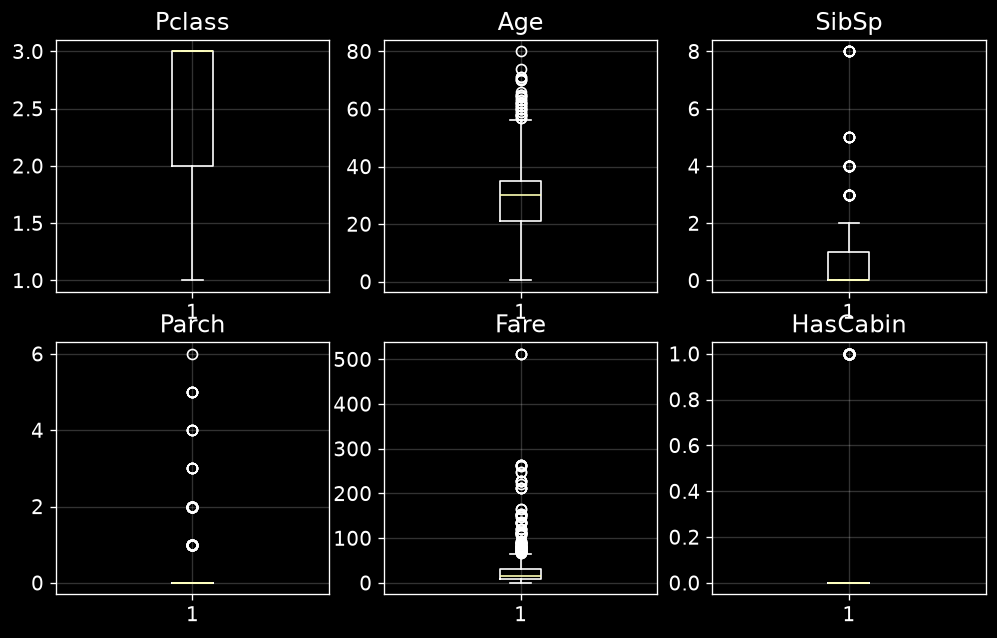

In [43]:
fig, axes = plt.subplots(2, 3)

for ax, feature in zip(axes.flat, numerical_features):
    ax.boxplot(
        baseline_df[feature].dropna()
    )
    ax.set_title(feature)
    
plt.show()

## Outlier Analysis — Conclusions

Several numerical features contain extreme values.

`Age`, `SibSp`, and `Parch` outliers correspond to valid passenger characteristics and should not be removed.

`Fare` contains strong right-skewness with several very large values. A logarithmic transformation (`log1p`) may reduce the impact of extreme values and will be evaluated during model training.

Outlier handling decisions will be validated using cross-validation rather than based only on descriptive statistics.

In [44]:
baseline_df["Fare_log"] = np.log1p(
    baseline_df["Fare"]
)

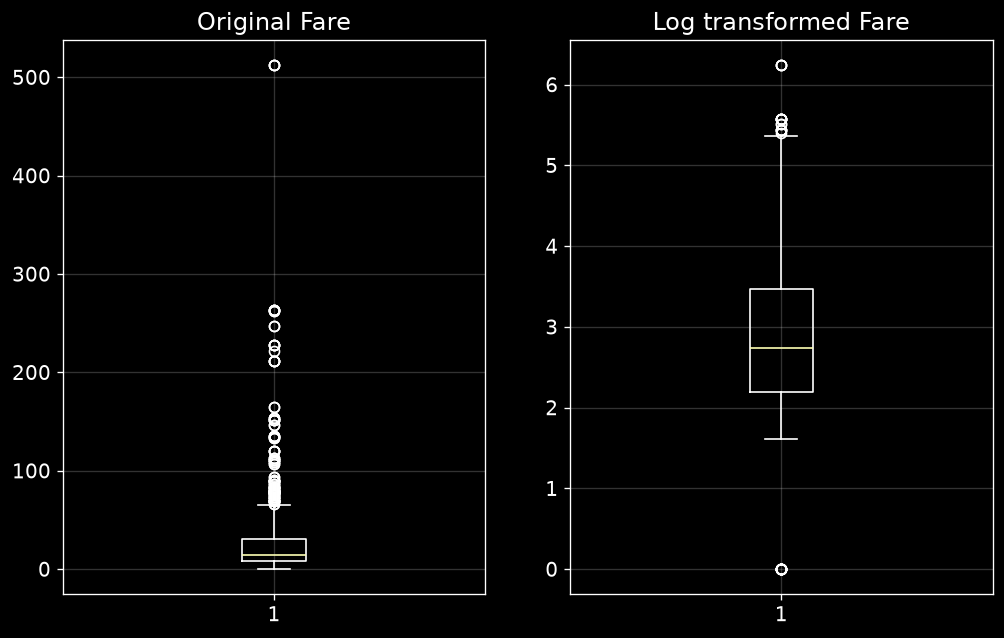

In [45]:
fig, axes = plt.subplots(1, 2)

axes[0].boxplot(
    baseline_df["Fare"]
)
axes[0].set_title("Original Fare")


axes[1].boxplot(
    baseline_df["Fare_log"]
)
axes[1].set_title("Log transformed Fare")

plt.show()

### Fare Outliers

The `Fare` feature contains several extreme values. However, these values represent real passengers with expensive tickets rather than data errors.

Instead of removing these observations, a logarithmic transformation was considered.

The transformation:

`log1p(Fare) = log(1 + Fare)`

reduces the impact of extreme values and decreases the right skewness of the distribution while preserving all observations.

The original and transformed versions of `Fare` will be compared during model evaluation.

In [46]:
baseline_df.columns

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'HasCabin', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Fare_log'],
      dtype='str')

In [48]:
baseline_raw_fare_df = baseline_df.drop(
    columns=["Fare_log"]
)

baseline_log_fare_df = baseline_df.drop(
    columns=["Fare"]
)

In [49]:
baseline_raw_fare_df.columns

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare',
       'HasCabin', 'Embarked_C', 'Embarked_Q', 'Embarked_S'],
      dtype='str')

In [50]:
baseline_log_fare_df.columns

Index(['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'HasCabin',
       'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Fare_log'],
      dtype='str')

In [52]:
processed_dir = Path("../data/processed")

processed_dir.mkdir(
    parents=True,
    exist_ok=True
)

baseline_raw_fare_df.to_csv(
    processed_dir / "baseline.csv",
    index=False
)

baseline_raw_fare_df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,Embarked_C,Embarked_Q,Embarked_S
0,0,3,1,22.0,1,0,7.2500,0,False,False,True
1,1,1,0,38.0,1,0,71.2833,1,True,False,False
2,1,3,0,26.0,0,0,7.9250,0,False,False,True
3,1,1,0,35.0,1,0,53.1000,1,False,False,True
4,0,3,1,35.0,0,0,8.0500,0,False,False,True
